[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/04_fingerprints_similarity.ipynb)

# 04 · Molecular Fingerprints and Similarity

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

*Similar molecules tend to have similar properties.* This **similarity principle** underlies
virtual screening, nearest-neighbour QSAR, clustering, and data splitting. To use it, we need
a way to turn molecules into comparable bit vectors (**fingerprints**) and a similarity metric.

**Learning objectives.** By the end of this notebook you will be able to:

- explain what a structural fingerprint is and how Morgan (ECFP-like) and MACCS fingerprints differ
- compute Tanimoto and Dice similarity between molecules
- run a similarity search against a dataset of ~7,000 compounds
- recognize why a similarity value depends on the fingerprint you choose

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


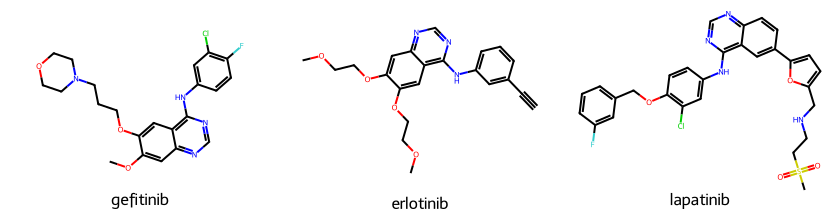

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator

egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv")
egfr["mol"] = egfr["smiles"].apply(Chem.MolFromSmiles)

def by_id(chembl_id):
    return egfr.loc[egfr.compound_id == chembl_id, "mol"].iloc[0]

gefitinib, erlotinib, lapatinib = by_id("CHEMBL939"), by_id("CHEMBL553"), by_id("CHEMBL554")
Draw.MolsToGridImage([gefitinib, erlotinib, lapatinib], legends=["gefitinib", "erlotinib", "lapatinib"],
                     subImgSize=(280, 220))

All three are approved EGFR inhibitors built on a 4-anilinoquinazoline core.

## 1. Morgan fingerprints (ECFP-like)

The Morgan algorithm looks at every atom and its neighbourhood out to a given **radius**
(radius 2 ≈ ECFP4), hashes each circular environment to an integer, and sets the corresponding
bit in a fixed-length vector (here 2,048 bits).

In [3]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

fp_gef = mfpgen.GetFingerprint(gefitinib)
print("length:", fp_gef.GetNumBits(), "| bits set:", fp_gef.GetNumOnBits())
print("first on-bits:", list(fp_gef.GetOnBits())[:10])

length: 2048 | bits set: 60
first on-bits: [13, 80, 191, 216, 249, 329, 366, 378, 465, 489]


Which substructure does a bit stand for? Ask the generator for the *bit info* and draw it.

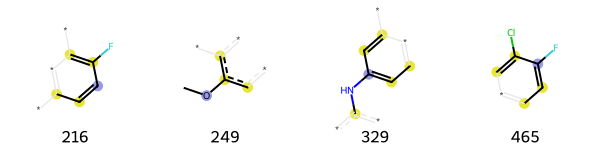

In [4]:
ao = rdFingerprintGenerator.AdditionalOutput()
ao.AllocateBitInfoMap()
fp = mfpgen.GetFingerprint(gefitinib, additionalOutput=ao)
bit_info = ao.GetBitInfoMap()
bits = [b for b in fp.GetOnBits() if bit_info[b][0][1] == 2][:4]   # a few radius-2 environments
Draw.DrawMorganBits([(gefitinib, b, bit_info) for b in bits], molsPerRow=4, legends=[str(b) for b in bits])

## 2. Tanimoto similarity

For two bit vectors A and B: **Tanimoto = |A ∩ B| / |A ∪ B|**, from 0 (no shared bits) to 1 (identical fingerprints).

In [5]:
fps = {name: mfpgen.GetFingerprint(m) for name, m in
       [("gefitinib", gefitinib), ("erlotinib", erlotinib), ("lapatinib", lapatinib)]}
names = list(fps)
sim = pd.DataFrame([[DataStructs.TanimotoSimilarity(fps[a], fps[b]) for b in names] for a in names],
                   index=names, columns=names)
sim.round(2)

,gefitinib,erlotinib,lapatinib
gefitinib,1.00,0.41,0.32
erlotinib,0.41,1.00,0.28
lapatinib,0.32,0.28,1.00


Even though a chemist sees the same core immediately, Morgan Tanimoto values between these
drugs are modest. Morgan fingerprints are sensitive to side chains. A Tanimoto of 0.3–0.4 is
*not* "unrelated" for ECFP4.

## 3. MACCS keys: a dictionary-based fingerprint

MACCS uses 166 predefined structural questions (e.g. "is there a ring of size 6?"). Fewer, more
general bits give **higher** similarity values for the same pair.

In [6]:
maccs = {name: MACCSkeys.GenMACCSKeys(m) for name, m in
         [("gefitinib", gefitinib), ("erlotinib", erlotinib), ("lapatinib", lapatinib)]}
sim_maccs = pd.DataFrame([[DataStructs.TanimotoSimilarity(maccs[a], maccs[b]) for b in names] for a in names],
                         index=names, columns=names)
sim_maccs.round(2)

,gefitinib,erlotinib,lapatinib
gefitinib,1.00,0.69,0.67
erlotinib,0.69,1.00,0.59
lapatinib,0.67,0.59,1.00


## 4. Similarity search over a dataset

`BulkTanimotoSimilarity` compares one fingerprint against a list very quickly.

In [7]:
egfr["fp"] = [mfpgen.GetFingerprint(m) for m in egfr["mol"]]
egfr["sim_to_gefitinib"] = DataStructs.BulkTanimotoSimilarity(fp_gef, list(egfr["fp"]))

hits = (egfr[egfr.compound_id != "CHEMBL939"]          # exclude the query itself
        .sort_values("sim_to_gefitinib", ascending=False).head(8))
hits[["compound_id", "sim_to_gefitinib", "p_activity"]]

,compound_id,sim_to_gefitinib,p_activity
3011,CHEMBL4448162,0.857143,9.00
3522,CHEMBL4858176,0.818182,4.60
3139,CHEMBL4534611,0.805970,8.18
3222,CHEMBL4586581,0.805970,8.08
843,CHEMBL2425092,0.782609,7.25
2218,CHEMBL384699,0.776119,7.29
844,CHEMBL2425093,0.771429,7.44
835,CHEMBL2425084,0.764706,7.60


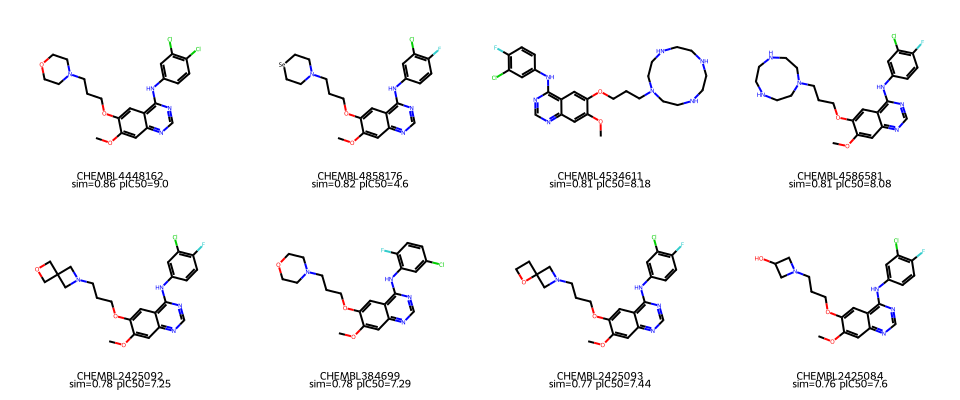

In [8]:
Draw.MolsToGridImage(list(hits["mol"]), molsPerRow=4, subImgSize=(240, 200),
                     legends=[f"{c}\nsim={s:.2f} pIC50={p}" for c, s, p in
                              zip(hits.compound_id, hits.sim_to_gefitinib, hits.p_activity)])

## 5. What do similarity values look like across a dataset?

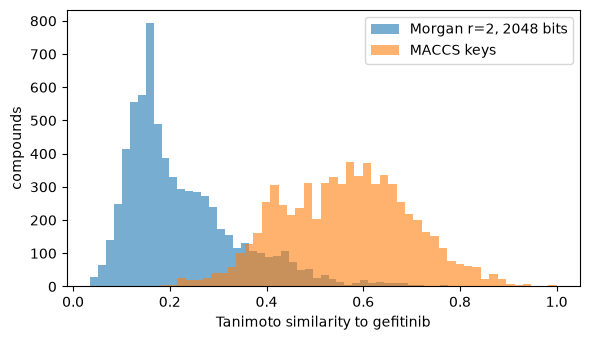

median Morgan: 0.188 | median MACCS: 0.568


In [9]:
egfr["maccs"] = [MACCSkeys.GenMACCSKeys(m) for m in egfr["mol"]]
egfr["maccs_sim_to_gefitinib"] = DataStructs.BulkTanimotoSimilarity(maccs["gefitinib"], list(egfr["maccs"]))
others = egfr[egfr.compound_id != "CHEMBL939"]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(others["sim_to_gefitinib"], bins=50, alpha=0.6, label="Morgan r=2, 2048 bits")
ax.hist(others["maccs_sim_to_gefitinib"], bins=50, alpha=0.6, label="MACCS keys")
ax.set_xlabel("Tanimoto similarity to gefitinib"); ax.set_ylabel("compounds"); ax.legend()
plt.tight_layout(); plt.show()
print("median Morgan:", others["sim_to_gefitinib"].median().round(3),
      "| median MACCS:", others["maccs_sim_to_gefitinib"].median().round(3))

**Lesson:** a similarity threshold only makes sense together with the fingerprint that produced it.
"Similar = Tanimoto > 0.85" is a MACCS-era rule of thumb that does not transfer to Morgan fingerprints.

## 6. Does similarity predict activity?

If the similarity principle holds, compounds very similar to gefitinib should be potent more often.

In [10]:
bins = pd.cut(others["sim_to_gefitinib"], [0, 0.2, 0.3, 0.4, 0.5, 1.0])
others.groupby(bins, observed=True)["p_activity"].agg(["size", "median"]).round(2)

,size,median
sim_to_gefitinib,,
"(0.0, 0.2]",3747,6.76
"(0.2, 0.3]",1681,7.20
"(0.3, 0.4]",784,7.43
"(0.4, 0.5]",449,7.58
"(0.5, 1.0]",209,7.62


### ✏️ Exercise 1

Compute the Morgan (radius 2, 2048 bits) Tanimoto similarity between aspirin (`CC(=O)Oc1ccccc1C(=O)O`) and paracetamol (`CC(=O)Nc1ccc(O)cc1`).

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
a = mfpgen.GetFingerprint(Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O"))
p = mfpgen.GetFingerprint(Chem.MolFromSmiles("CC(=O)Nc1ccc(O)cc1"))
print(round(DataStructs.TanimotoSimilarity(a, p), 3))
```

</details>

### ✏️ Exercise 2

How many EGFR compounds (excluding erlotinib itself, `CHEMBL553`) have a Morgan Tanimoto ≥ 0.5 to erlotinib?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
fp_erl = mfpgen.GetFingerprint(erlotinib)
sims = np.array(DataStructs.BulkTanimotoSimilarity(fp_erl, list(egfr["fp"])))
mask = (sims >= 0.5) & (egfr["compound_id"] != "CHEMBL553").values
print(mask.sum())
```

</details>

### ✏️ Exercise 3

The **Dice** coefficient is 2|A∩B| / (|A|+|B|). Recompute the gefitinib/erlotinib/lapatinib matrix with `DataStructs.DiceSimilarity`. Is Dice always ≥ Tanimoto?

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
dice = pd.DataFrame([[DataStructs.DiceSimilarity(fps[a], fps[b]) for b in names] for a in names],
                    index=names, columns=names)
print(dice.round(2))
print("Dice >= Tanimoto everywhere:", bool((dice.values >= sim.values - 1e-12).all()))
```

</details>

## Key takeaways

- Morgan fingerprints encode circular atom environments; MACCS answers 166 fixed questions.
- Tanimoto is the standard similarity metric, but its scale depends on the fingerprint.
- Bulk similarity search over thousands of compounds takes milliseconds.

**Next:** [05 · Substructure search and SMARTS](05_substructure_smarts.ipynb).